# Customer Churn Prediction 
#### Multi-Algorithm Classification Showdown

A telecom retention team is losing paying subscribers every month and cannot predict who will leave. Using the **IBM Telco Customer Churn** dataset (7,043 customers, 21 columns) this notebook builds and compares four classifiers - **KNN, Gaussian Naive Bayes, SVM and Decision Tree** - handles class imbalance with **SMOTE** and **class_weight**, and picks the model to deploy based on the business cost of a missed churner.

**Contents:** 1 Theory · 2 Load & EDA · 3 Preprocessing & Feature Engineering · 4 KNN & Naive Bayes · 5 SVM & Decision Tree · 6 Comparison · 7 Error Analysis · 8 Pipeline, Pickle Export & Summary

## Step 1 - Problem Framing & Theory Notes

**1. What is Customer Churn? Why is predicting it valuable? (CAC vs CLV)**
- Churn means a subscriber stops using the service (here: `Churn = Yes`).
- **CAC** (Customer Acquisition Cost) is what it costs to win a new customer; **CLV** (Customer Lifetime Value) is the revenue a customer brings over their stay. Winning a replacement usually costs far more than keeping an existing customer, whose CLV is still accruing.
- A churn model lets a company like Jio or Airtel spend a limited retention budget (calls, offers) on the customers most likely to leave.

**2. Confusion Matrix (TP, TN, FP, FN) in the churn context**
- **TP**: predicted churn, customer really churned. **TN**: predicted stay, customer stayed. **FP**: predicted churn, customer actually stayed. **FN**: predicted stay, customer actually left.
- **False Negative = expensive:** the customer leaves silently and the company loses the entire remaining CLV, with no chance to react.
- **False Positive = cheap:** a retention call or small discount is wasted on a loyal customer.

**3. Class Imbalance & SMOTE**
- Class imbalance means one class is much rarer than the other, so a model can score high accuracy by always predicting the majority class.
- The Telco dataset has **1,869 churners vs 5,174 retained (about 26.5% churn, roughly 2.8 : 1)** - a moderate imbalance.
- **SMOTE** creates *synthetic* minority samples by interpolating between a churner and one of its k nearest churner neighbours, so the model sees a balanced training set without simple duplication.

**4. How the four algorithms work**
- **KNN:** classifies a customer by majority vote of the *k* closest customers in feature space; needs scaled features and has no real training phase.
- **Gaussian Naive Bayes:** applies Bayes' theorem assuming features are independent and (per class) normally distributed; multiplies class prior with feature likelihoods.
- **SVM (RBF):** finds the maximum-margin boundary between classes, using the RBF kernel to bend it non-linearly; `C` controls margin softness.
- **Decision Tree:** repeatedly splits customers on the feature/threshold that best separates churners from non-churners (Gini), giving human-readable rules.

**5. When would you choose Precision over Recall?**
- When each flagged customer triggers an **expensive action** - e.g. a large handset subsidy or a personal field visit - and the budget is small, false alarms burn money, so Precision becomes the primary metric.
- Recall is preferred when the intervention is cheap (SMS, short call) and missing a churner is costly.

#### Imports

In [2]:
import os
import time
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                                roc_curve, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

## Step 2 - Dataset Loading & Exploratory Data Analysis

### 2.1 Load & Inspect

In [3]:
df = pd.read_csv("../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"Shape : {df.shape}")
df.head()

Shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [6]:
vc = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": vc, "percent": pct.round(2)}))
print(f"\nImbalance ratio (Retained : Churned) = {vc['No'] / vc['Yes']:.2f} : 1")

       count  percent
Churn                
No      5174    73.46
Yes     1869    26.54

Imbalance ratio (Retained : Churned) = 2.77 : 1


**Interpretation:** 1,869 of 7,043 customers churned (**26.5%**), a ratio of about **2.8 : 1**. The imbalance is moderate: always predicting "No Churn" would already give ~73.5% accuracy while catching zero churners, so accuracy alone is misleading and Recall / F1 for the churn class are the metrics that matter.

### 2.2 Univariate Analysis

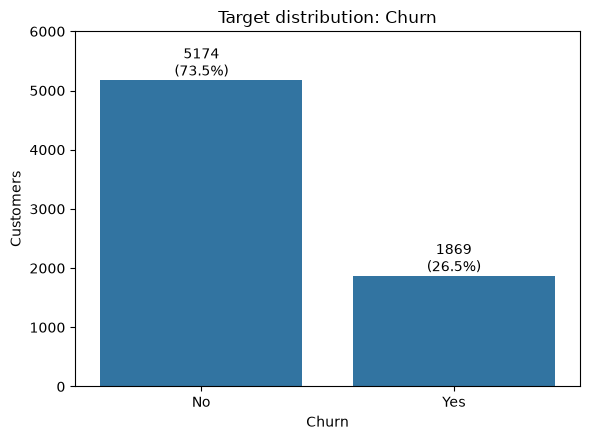

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df, x="Churn", ax=ax)

for c in ax.containers:
    ax.bar_label(c, labels=[f"{int(v)}\n({v/len(df):.1%})" for v in c.datavalues])
    
ax.set_title("Target distribution: Churn")
ax.set_ylabel("Customers")
ax.set_ylim(0, 6000)
plt.tight_layout()
plt.savefig("../images/01.target_distribution.png")
plt.show()

**Interpretation:** The target is clearly skewed towards retained customers (73.5% vs 26.5%), confirming that class imbalance has to be handled (SMOTE / class_weight) and that evaluation must look beyond accuracy.

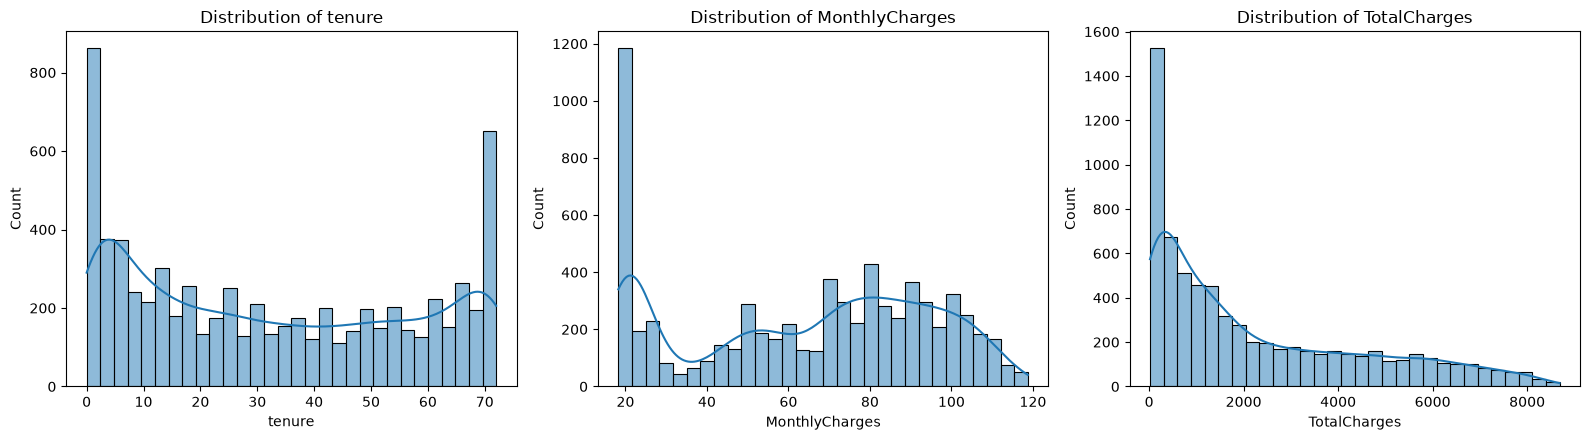

In [16]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
    
plt.tight_layout()
plt.savefig("../images/02.distribution_of_tenure_monthlycharges_totalcharges.png")
plt.show()

**Interpretation:** **tenure** is U-shaped - many brand-new customers (0-5 months) and many very loyal ones (70+ months). **MonthlyCharges** is multi-modal with a large group of low-priced plans (about 20 USD, phone-only) and a bulk between 70 and 100 USD. **TotalCharges** is right-skewed (skew about 0.96) because it grows with tenure, which is why it is scaled before modelling.

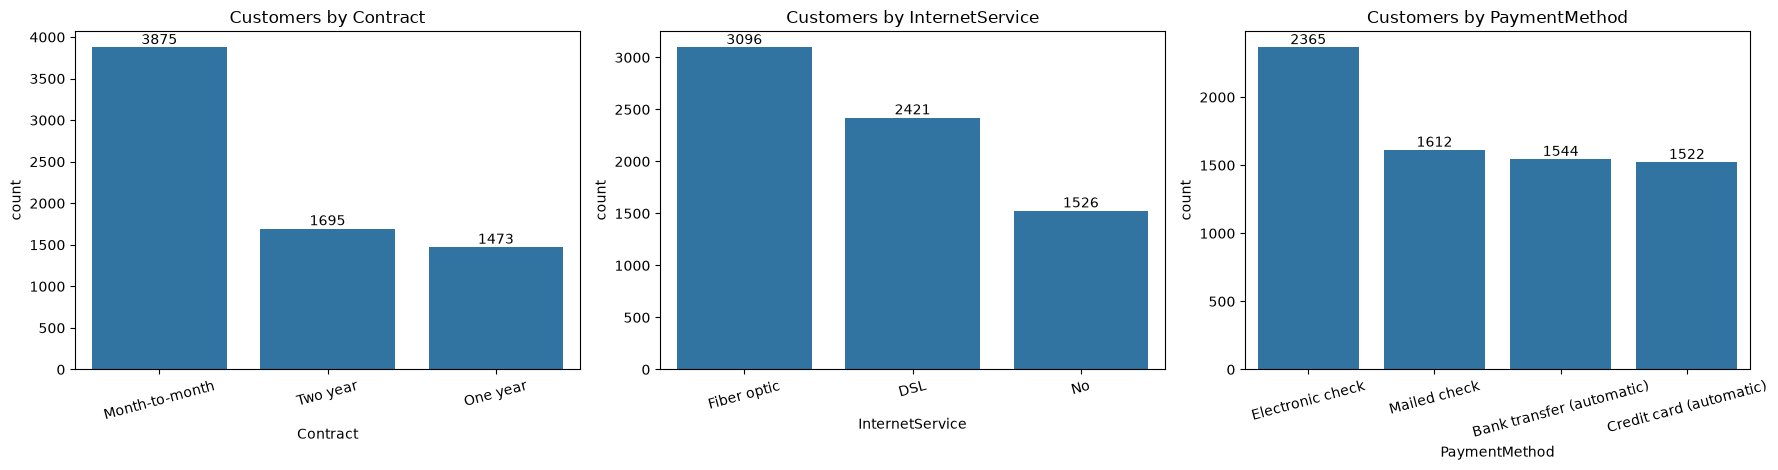

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    sns.countplot(data=df, x=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(f"Customers by {col}"); ax.tick_params(axis="x", rotation=15)
    for c in ax.containers: ax.bar_label(c)
    
plt.tight_layout()
plt.savefig("../images/03.number_of_customers.png")
plt.show()

**Interpretation:** 55% of customers are on **month-to-month** contracts, 44% use **fibre optic** internet and **electronic check** is the most common payment method (33.6%). These are exactly the groups that turn out to be risky in the bivariate analysis below.

### 2.3 Bivariate Analysis

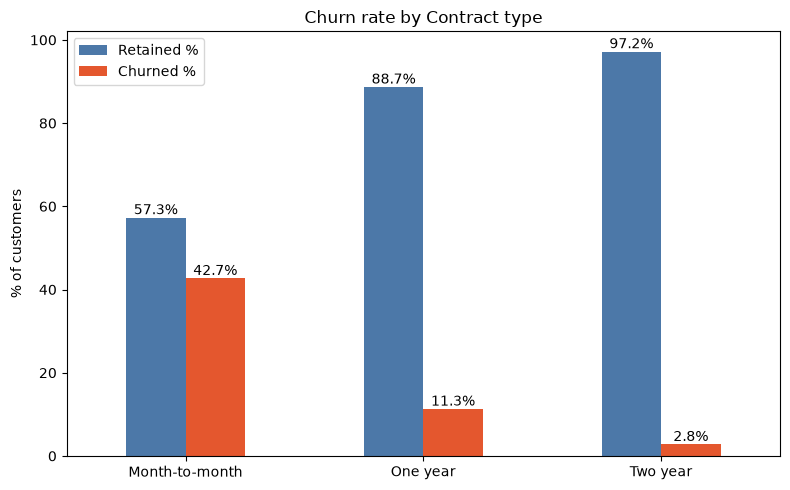

                Retained %  Churned %
Contract                             
Month-to-month        57.3       42.7
One year              88.7       11.3
Two year              97.2        2.8


In [12]:
ct = pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(1)
ct.columns = ["Retained %", "Churned %"]
ax = ct.loc[["Month-to-month", "One year", "Two year"]].plot(kind="bar", color=["#4C78A8", "#E4572E"], figsize=(8, 5), rot=0)
for c in ax.containers: 
    ax.bar_label(c, fmt="%.1f%%")
    
ax.set_title("Churn rate by Contract type")
ax.set_ylabel("% of customers")
ax.set_xlabel("")
plt.tight_layout()
plt.savefig("../images/04.churn_rate_by_contract_type.png")
plt.show()
print(ct)

**Interpretation:** Contract type is a very strong churn driver: **42.7%** of month-to-month customers churn versus **11.3%** on one-year and only **2.8%** on two-year contracts. Contracts lock customers in, so any retention strategy should push month-to-month users towards longer plans.

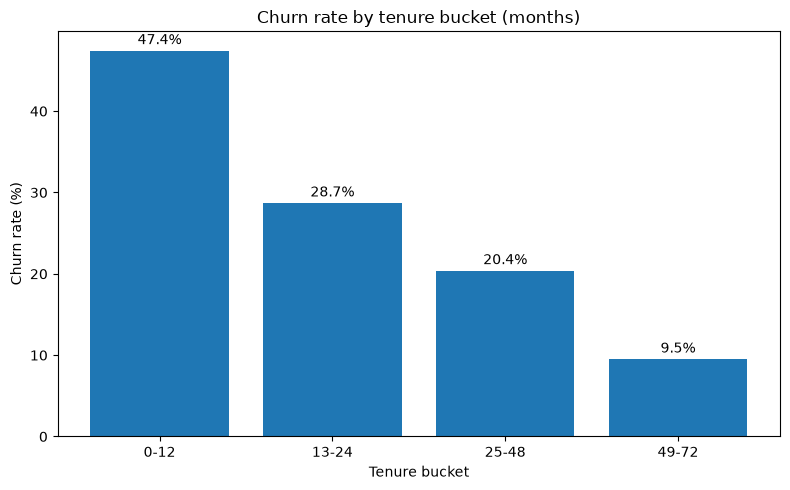

In [17]:
df["tenure_bucket"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"])
rate = df.groupby("tenure_bucket", observed=True)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(rate.index.astype(str), rate.values)

for i, v in enumerate(rate.values): 
    ax.text(i, v + 0.8, f"{v:.1f}%", ha="center")
    
ax.set_title("Churn rate by tenure bucket (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Tenure bucket")
plt.tight_layout()
plt.savefig("../images/05.charn_rate_by_tenure_bucket.png")
plt.show()
df.drop(columns="tenure_bucket", inplace=True)

**Interpretation:** Churn falls steadily with tenure: **47.4%** in the first year, 28.7% (13-24 months), 20.4% (25-48 months) and only **9.5%** after four years. The first 12 months are the critical window for retention.

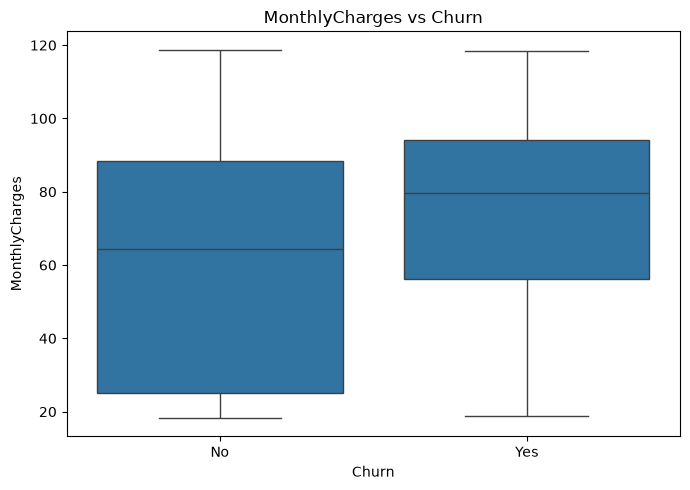

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("MonthlyCharges vs Churn")
plt.tight_layout()
plt.savefig("../images/06.monthly_charges_wise_churn.png")
plt.show()
print(df.groupby("Churn")["MonthlyCharges"].agg(["mean", "median"]).round(2))

**Interpretation:** Churners pay more per month (median **79.65** vs 64.43 USD; mean 74.44 vs 61.27 USD). Higher bills - typically fibre plans with add-ons - go together with higher churn, so price sensitivity is a likely driver.

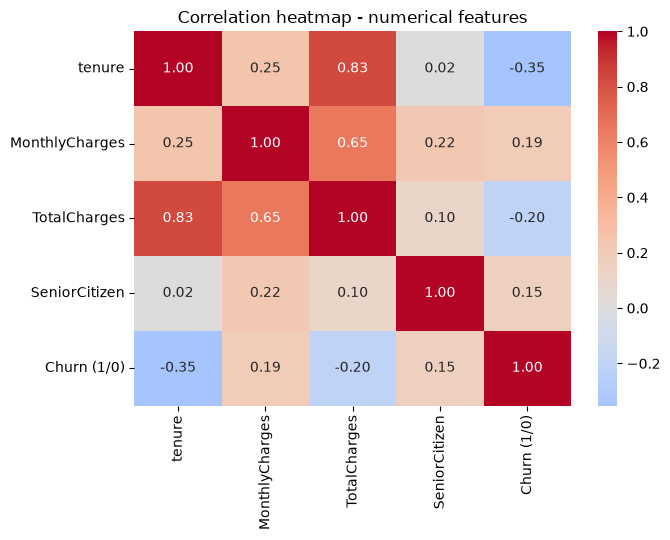

In [19]:
num_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
num_df["Churn (1/0)"] = (df["Churn"] == "Yes").astype(int)

plt.figure(figsize=(7, 5.5))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap - numerical features")
plt.tight_layout()
plt.savefig("../images/07.heatmap.png")
plt.show()

**Interpretation:** tenure and TotalCharges are strongly correlated (**0.83**), and MonthlyCharges correlates with TotalCharges (0.65), so there is some multicollinearity. Against churn: tenure is the strongest numeric signal (**-0.35**), then TotalCharges (-0.20), MonthlyCharges (+0.19) and SeniorCitizen (+0.15). Linear correlations are moderate, so tree-based / non-linear models may help.

In [20]:
seg = (df["Contract"] == "Month-to-month") & (df["MonthlyCharges"] > df["MonthlyCharges"].median()) & (df["tenure"] <= 12)
churn_flag = (df["Churn"] == "Yes")
print(f"High-risk segment size : {seg.sum()} customers ({seg.mean():.1%} of base)")
print(f"Churn rate in segment : {churn_flag[seg].mean():.1%}")
print(f"Churn rate everywhere else: {churn_flag[~seg].mean():.1%}")
print(f"Overall churn rate : {churn_flag.mean():.1%}")

High-risk segment size : 812 customers (11.5% of base)
Churn rate in segment : 70.0%
Churn rate everywhere else: 20.9%
Overall churn rate : 26.5%


**Interpretation:** The EDA confirms the key insight. Month-to-month customers with above-median MonthlyCharges and tenure of 12 months or less make up only 11.5% of the base, yet **70% of them churn** versus 20.9% for everyone else - more than 2.6x the overall rate.

## Step 3 - Data Preprocessing & Feature Engineering

**Order of operations (to avoid data leakage):** cleaning, feature engineering and the fixed Yes/No mappings are row-wise and need no learning, so they are wrapped in one function `prepare()` (the Streamlit app reuses the same logic). The **train-test split is done next**, and only then are the scaler / one-hot encoder fitted (on train only) and SMOTE applied (on train only). Sections are numbered as in the exam sheet, so the split appears as 3.4 and scaling / SMOTE follow as 3.5 and 3.6.

### Drop & Clean, Feature Engineering, and Encoding (stateless transformations)

In [21]:
TC_MEDIAN = df["TotalCharges"].median()
ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
BINARY_YES = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "MultipleLines"]   
TENURE_ORDER = {"New": 0, "Mid": 1, "Senior": 2, "Loyal": 3}                                  

def prepare(raw):
    """Raw Telco rows -> model-ready (un-scaled) feature frame. Works with or without customerID / Churn."""
    d = raw.copy()
    d = d.drop(columns=["customerID"], errors="ignore")
    d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce").fillna(TC_MEDIAN)
    
    grp = pd.cut(d["tenure"], bins=[-1, 12, 36, 60, np.inf], labels=list(TENURE_ORDER)).astype(str)
    d["tenure_group"] = grp.map(TENURE_ORDER).astype(int)       
    d["num_services"] = (d[ADDONS] == "Yes").sum(axis=1)
    d["AutoPay"] = d["PaymentMethod"].str.contains("automatic", case=False).astype(int)
    
    for c in BINARY_YES:
        d[c] = (d[c] == "Yes").astype(int)
    d["gender"] = (d["gender"] == "Male").astype(int)
    if "Churn" in d.columns:
        d["Churn"] = (d["Churn"] == "Yes").astype(int)
    
    return d.drop(columns=ADDONS)

data = prepare(df)
print("Shape after preparation:", data.shape)
data.head()

Shape after preparation: (7043, 17)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group,num_services,AutoPay
0,0,0,1,0,1,0,0,DSL,Month-to-month,1,Electronic check,29.85,29.85,0,0,1,0
1,1,0,0,0,34,1,0,DSL,One year,0,Mailed check,56.95,1889.50,0,1,2,0
2,1,0,0,0,2,1,0,DSL,Month-to-month,1,Mailed check,53.85,108.15,1,0,2,0
3,1,0,0,0,45,0,0,DSL,One year,0,Bank transfer (automatic),42.30,1840.75,0,2,3,1
4,0,0,0,0,2,1,0,Fiber optic,Month-to-month,1,Electronic check,70.70,151.65,1,0,0,0


In [22]:
print("tenure_group counts (0=New 0-12, 1=Mid 13-36, 2=Senior 37-60, 3=Loyal 61+):")
print(data["tenure_group"].value_counts().sort_index().to_string())
print("\nnum_services distribution:")
print(data["num_services"].value_counts().sort_index().to_string())
print(f"\nAutoPay customers: {data['AutoPay'].mean():.1%}")
print("\nChurn rate by tenure_group:\n", data.groupby("tenure_group")["Churn"].mean().round(3).to_string())

tenure_group counts (0=New 0-12, 1=Mid 13-36, 2=Senior 37-60, 3=Loyal 61+):
tenure_group
0    2186
1    1856
2    1594
3    1407

num_services distribution:
num_services
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284

AutoPay customers: 43.5%

Churn rate by tenure_group:
 tenure_group
0    0.474
1    0.255
2    0.166
3    0.066


**Interpretation:** The engineered features behave sensibly: churn drops monotonically from **47.4% (New)** to **6.6% (Loyal)** across **tenure_group**, so the ordinal encoding 0-3 preserves a meaningful order. **num_services** counts the six add-ons (0 to 6) and **AutoPay** flags the 43.5% of customers on automatic payment.

### 3.4 Train-Test Split (80 / 20, stratified)

In [25]:
X = data.drop(columns="Churn")
y = data["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| y_train:", y_train.shape, "| y_test:", y_test.shape)
print(f"Churn rate --> train: {y_train.mean():.3%}  |  test: {y_test.mean():.3%}")

X_train: (5634, 16) | X_test: (1409, 16) | y_train: (5634,) | y_test: (1409,)
Churn rate --> train: 26.535%  |  test: 26.544%


### 3.5 Encoding (one-hot) & Scaling - fitted on the training set only

In [26]:
OHE_COLS   = ["InternetService", "Contract", "PaymentMethod"]
SCALE_COLS = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]

preprocessor = ColumnTransformer(
    [("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False), OHE_COLS),
    ("scale", StandardScaler(), SCALE_COLS)],
    remainder="passthrough", 
    verbose_feature_names_out=False).set_output(transform="pandas")

X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)
print("Processed feature matrix:", X_train_p.shape)
print("Features:", list(X_train_p.columns))
X_train_p[SCALE_COLS].describe().loc[["mean", "std"]].round(3)

Processed feature matrix: (5634, 23)
Features: ['InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_services', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'PaperlessBilling', 'tenure_group', 'AutoPay']


,tenure,MonthlyCharges,TotalCharges,num_services
mean,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


**Note:** KNN and SVM are distance-based, so scaling is essential for them. Decision Tree and Naive Bayes do not need it, but all models receive the same scaled matrix so that the comparison is fair.

### 3.6 Handle Class Imbalance (SMOTE on the training set only)

Class counts in training set (before SMOTE): {0: 4139, 1: 1495}
Class counts in training set (after SMOTE) : {0: 4139, 1: 4139}
Test set (untouched) : {0: 1035, 1: 374}


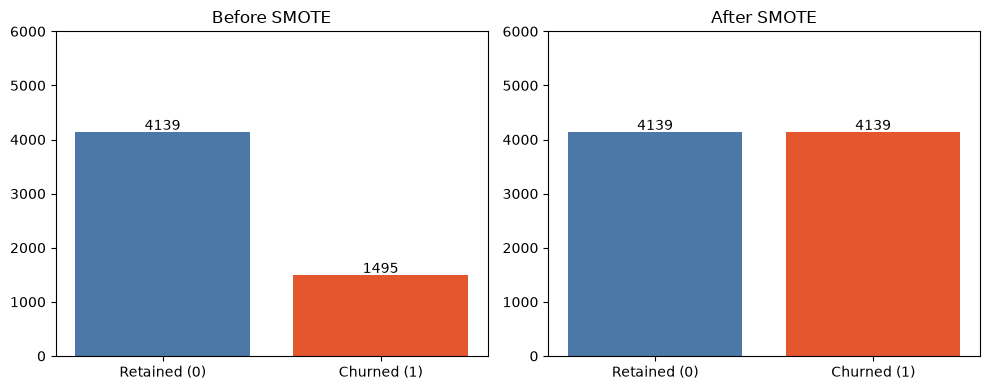

In [27]:
print("Class counts in training set (before SMOTE):", y_train.value_counts().sort_index().to_dict())
smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train_p, y_train)
print("Class counts in training set (after SMOTE) :", y_train_sm.value_counts().sort_index().to_dict())
print("Test set (untouched) :", y_test.value_counts().sort_index().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for a, (lbl, yy) in zip(ax, [("Before SMOTE", y_train), ("After SMOTE", y_train_sm)]):
    v = yy.value_counts().sort_index()
    a.bar(["Retained (0)", "Churned (1)"], v.values, color=["#4C78A8", "#E4572E"])
    
    for i, n in enumerate(v.values): 
        a.text(i, n + 40, str(n), ha="center")
        
    a.set_title(lbl)
    a.set_ylim(0, 6000)
    
plt.tight_layout()
plt.savefig("../images/08.SMOTE_comparission.png")
plt.show()

**Interpretation:** The training set has 4,139 retained vs 1,495 churned customers. After SMOTE both classes have **4,139** rows (2,644 synthetic churners added). The test set is untouched at 1,035 / 374, so the metrics below reflect realistic, imbalanced data.

**SMOTE Rule:** SMOTE is fitted on X_train / y_train only. The test set stays original (un-augmented) to simulate real-world evaluation.

### Evaluation helpers

In [28]:
results = {}
baseline_results = {}
models = {}
probas = {}
preds = {}

def fit_timed(model, X, y):
    t0 = time.perf_counter(); model.fit(X, y)
    return model, time.perf_counter() - t0

def evaluate(name, model, train_time, store=None):
    """Metrics on the untouched test set. Precision / Recall / F1 are for the Churn class."""
    pred = model.predict(X_test_p); proba = model.predict_proba(X_test_p)[:, 1]
    row = {"Model": name,
            "Accuracy": accuracy_score(y_test, pred), 
            "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), 
            "F1-Score": f1_score(y_test, pred),
            "AUC-ROC": roc_auc_score(y_test, proba), 
            "Training Time (s)": train_time
        }
    
    if store is not None:
        store[name] = row
    return row, pred, proba

def show_row(row):
    print("  ".join(f"{k}: {v:.4f}" if isinstance(v, float) 
                else f"{k}: {v}" for k, v in row.items() if k != "Model"))

def plot_cm(y_true, pred, title, save_path=None):
    cm = confusion_matrix(y_true, pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Retained", "Churned"], yticklabels=["Retained", "Churned"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()

def plot_roc(y_true, proba, title, save_path=None):
    fpr, tpr, _ = roc_curve(y_true, proba)
    auc = roc_auc_score(y_true, proba)
    plt.figure(figsize=(5.5, 4.5))
    plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
    plt.plot([0, 1], [0, 1], "k--", lw=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate (Recall)")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(save_path)
    plt.show()

## Step 4 - Model Building: KNN & Naive Bayes

### 4.1 K-Nearest Neighbours (KNN)

In [29]:
knn5, t = fit_timed(KNeighborsClassifier(n_neighbors=5), X_train_sm, y_train_sm)
row, _, _ = evaluate("KNN (k=5)", knn5, t, store=baseline_results)
print("KNN baseline (k=5) on test set:")
show_row(row)

KNN baseline (k=5) on test set:
Accuracy: 0.7189  Precision: 0.4799  Recall: 0.7032  F1-Score: 0.5705  AUC-ROC: 0.7795  Training Time (s): 0.0088


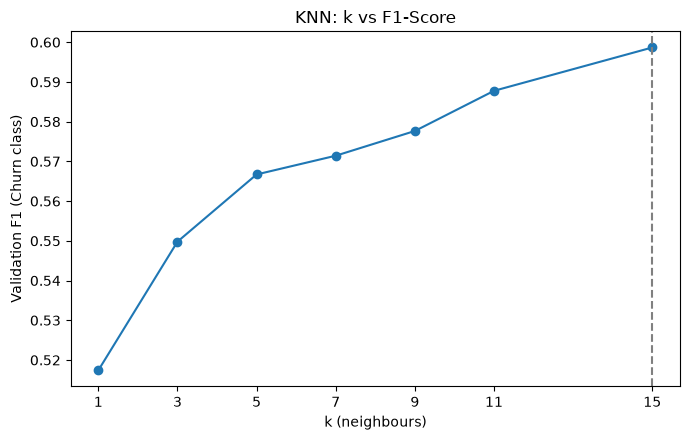

Best k: 15


In [34]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train_p, y_train, test_size=0.2, stratify=y_train, random_state=42)
X_tr_sm, y_tr_sm = SMOTE(random_state=42).fit_resample(X_tr, y_tr)

k_values = [1, 3, 5, 7, 9, 11, 15]
val_f1 = [f1_score(y_val, KNeighborsClassifier(n_neighbors=k).fit(X_tr_sm, y_tr_sm).predict(X_val)) for k in k_values]
best_k = k_values[int(np.argmax(val_f1))]

plt.figure(figsize=(7, 4.5))
plt.plot(k_values, val_f1, marker="o")
plt.axvline(best_k, ls="--", color="grey")
plt.xticks(k_values)
plt.xlabel("k (neighbours)")
plt.ylabel("Validation F1 (Churn class)")
plt.title("KNN: k vs F1-Score")
plt.tight_layout()
plt.savefig("../images/09.best_k.png")
plt.show()
print("Best k:", best_k)

**Interpretation:** Validation F1 rises steadily with k, from 0.52 at k = 1 (over-fitting to single neighbours) to **0.599 at k = 15**, the best value tried. Larger k smooths the decision boundary; the curve is still flattening, so values above 15 would give only marginal gains.

KNN (k=15) on test set:
Accuracy: 0.7218  Precision: 0.4854  Recall: 0.7995  F1-Score: 0.6040  AUC-ROC: 0.8173  Training Time (s): 0.0052


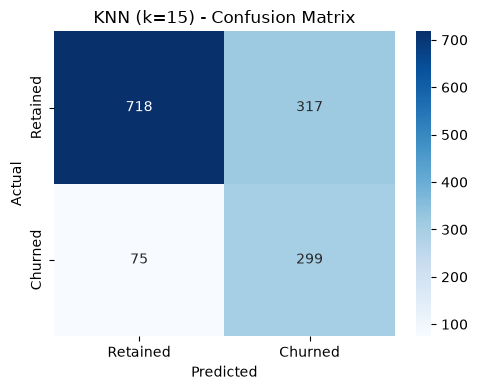

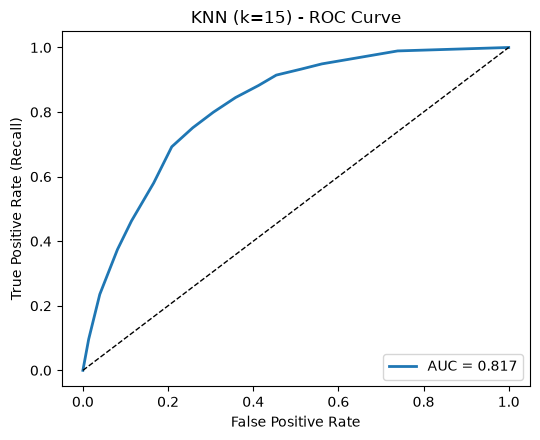

In [ ]:
knn, t = fit_timed(KNeighborsClassifier(n_neighbors=best_k), X_train_sm, y_train_sm)
row, preds["KNN"], probas["KNN"] = evaluate("KNN", knn, t, store=results)
models["KNN"] = knn
print(f"KNN (k={best_k}) on test set:")
show_row(row)

plot_cm(y_test, preds["KNN"], f"KNN (k={best_k}) - Confusion Matrix", "../images/10.KNN_confussion_matrix.png")
plot_roc(y_test, probas["KNN"], f"KNN (k={best_k}) - ROC Curve", "../images/11.KNN_ROC_curve.png")

**Interpretation:** Tuning k from 5 to 15 lifts Recall from 0.70 to **0.80** and F1 from 0.569 to **0.604**. KNN catches about 8 in 10 churners but precision is only 0.49, i.e. roughly half of the flagged customers are false alarms.

### 4.2 Naive Bayes - Gaussian NB

Gaussian NB on test set:
Accuracy: 0.7239  Precision: 0.4879  Recall: 0.8102  F1-Score: 0.6090  AUC-ROC: 0.8175  Training Time (s): 0.0072

class_prior_ learned by the model : [0.5 0.5]
Actual churn rate in original train: [0.735 0.265]


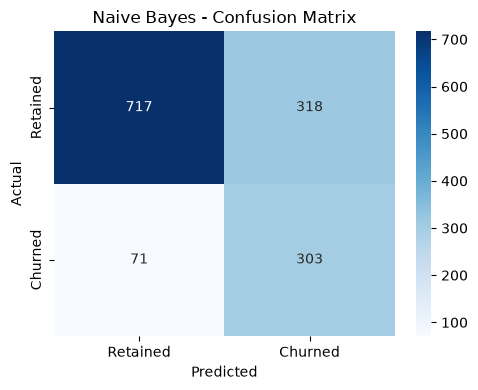

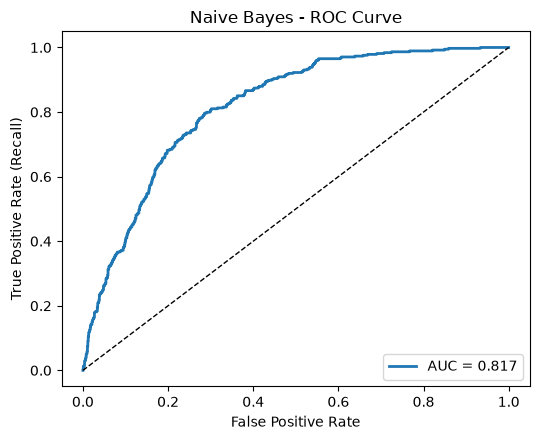

In [37]:
nb, t = fit_timed(GaussianNB(), X_train_sm, y_train_sm)
row, preds["Naive Bayes"], probas["Naive Bayes"] = evaluate("Naive Bayes", nb, t, store=results)
models["Naive Bayes"] = nb

print("Gaussian NB on test set:")
show_row(row)
print("\nclass_prior_ learned by the model :", nb.class_prior_.round(3))
print(f"Actual churn rate in original train: [{1 - y_train.mean():.3f} {y_train.mean():.3f}]")

plot_cm(y_test, preds["Naive Bayes"], "Naive Bayes - Confusion Matrix", "../images/12.Naive_Bayes_cm.png")
plot_roc(y_test, probas["Naive Bayes"], "Naive Bayes - ROC Curve", "../images/13.Naive_Bayes_roc_curve.png")

**Interpretation:** Gaussian NB reaches the **highest Recall (0.81)** of all models but with the lowest precision (0.49), so it flags many customers who would have stayed. Its learned **class_prior_** is **[0.5, 0.5]**, not the real [0.735, 0.265], because SMOTE balanced the training data - the priors match the *resampled* data, not the real churn rate.

**Does the independence assumption hold?** Only partly. Features such as **tenure**, **TotalCharges**, **MonthlyCharges** and **num_services** are clearly correlated (long-tenure customers have large totals, more services means higher bills), so the "naive" assumption is violated and the predicted probabilities are not well calibrated. Despite this, Naive Bayes often still ranks churners reasonably, which is why it can show a high recall.

**Reminder:** for churn prediction a False Negative costs more than a False Positive, so the analysis focuses on **Recall for the Churn class**.

## Step 5 - Model Building: SVM & Decision Tree

### 5.1 Support Vector Machine (SVM)

c:\Users\Rensee\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM baseline (C=1) on test set:
Accuracy: 0.7431  Precision: 0.5106  Recall: 0.7701  F1-Score: 0.6141  AUC-ROC: 0.8211  Training Time (s): 10.5510


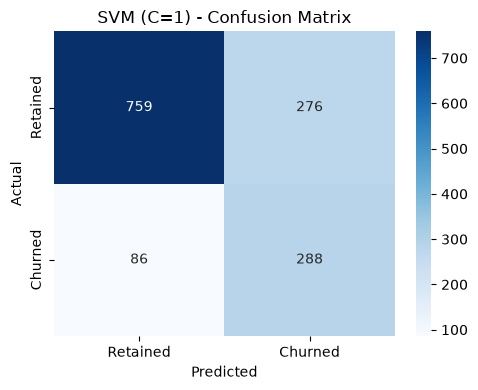

In [38]:
svm0, t = fit_timed(SVC(kernel="rbf", C=1, gamma="scale", probability=True, random_state=42), X_train_sm, y_train_sm)
row, pred0, _ = evaluate("SVM (C=1)", svm0, t, store=baseline_results)
print("SVM baseline (C=1) on test set:")
show_row(row)
plot_cm(y_test, pred0, "SVM (C=1) - Confusion Matrix", "../images/14.SVM_confussion_matrix.png")

C:\Users\Rensee\AppData\Local\Temp\ipykernel_14516\1499259409.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


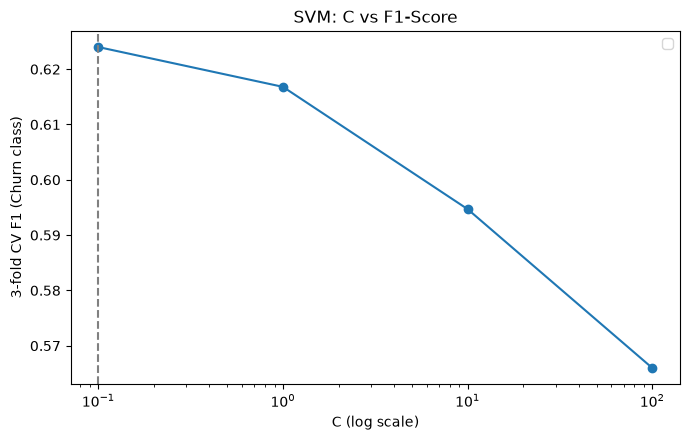

Best C: 0.1


In [40]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
C_values = [0.1, 1, 10, 100]
cv_f1 = []

for C in C_values:
    pipe = ImbPipeline([("smote", SMOTE(random_state=42)), 
                        ("svc", SVC(kernel="rbf", C=C, gamma="scale", random_state=42))])
    cv_f1.append(cross_val_score(pipe, X_train_p, y_train, cv=cv3, scoring="f1", n_jobs=-1).mean())
best_C = C_values[int(np.argmax(cv_f1))]

plt.figure(figsize=(7, 4.5))
plt.semilogx(C_values, cv_f1, marker="o")
plt.axvline(best_C, ls="--", color="grey")
plt.xlabel("C (log scale)")
plt.ylabel("3-fold CV F1 (Churn class)")
plt.title("SVM: C vs F1-Score")
plt.legend()
plt.tight_layout()
plt.savefig("../images/15.best_c.png")
plt.show()
print("Best C:", best_C)

**Interpretation:** 3-fold CV F1 is best for the **smallest C = 0.1 (0.624)** and falls as C grows (0.617 at C = 1, 0.595 at C = 10, 0.566 at C = 100). A large C fits the training data (including synthetic points) too tightly and over-fits, so a softer margin generalises better.

c:\Users\Rensee\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM (C=0.1) final test metrics:
Accuracy: 0.7452  Precision: 0.5134  Recall: 0.7674  F1-Score: 0.6152  AUC-ROC: 0.8262  Training Time (s): 10.2011


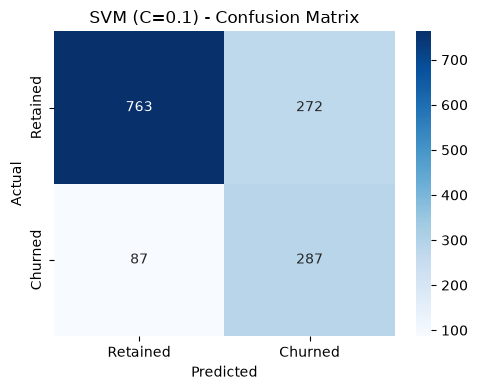

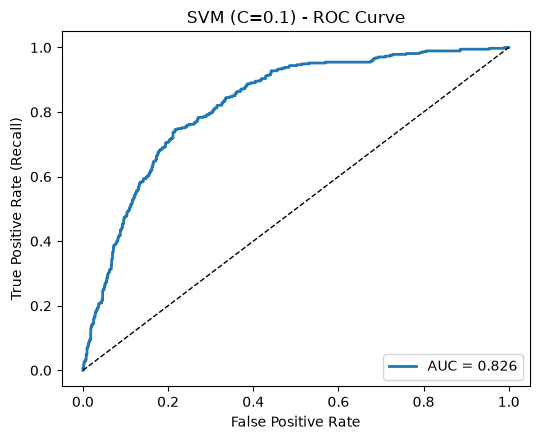

In [42]:
svm, t = fit_timed(SVC(kernel="rbf", C=best_C, gamma="scale", probability=True, random_state=42), X_train_sm, y_train_sm)
row, preds["SVM"], probas["SVM"] = evaluate("SVM", svm, t, store=results)
models["SVM"] = svm
print(f"SVM (C={best_C}) final test metrics:")
show_row(row)
plot_cm(y_test, preds["SVM"], f"SVM (C={best_C}) - Confusion Matrix", "../images/16.SVM_best_cm.png")
plot_roc(y_test, probas["SVM"], f"SVM (C={best_C}) - ROC Curve", "../images/17.SVM_best_roc_curve.png")

**Interpretation:** The tuned SVM (C = 0.1) gives Accuracy 0.745, Recall 0.767 and AUC 0.826. It has the strongest ranking quality among the non-tree models but the lowest Recall of the four and is by far the slowest to train (~11 s vs milliseconds for the others).

**Interpretability vs performance:** SVM with an RBF kernel is a black box - it cannot give the retention team a simple rule such as "month-to-month and fibre customers are risky", which makes it harder to trust and to turn into a campaign. The business has to decide whether any extra recall / AUC over a transparent tree is worth that loss of explainability.

### 5.2 Decision Tree Classifier

Decision Tree baseline (max_depth=5) on test set:
Accuracy: 0.7459  Precision: 0.5136  Recall: 0.8102  F1-Score: 0.6286  AUC-ROC: 0.8350  Training Time (s): 0.0481


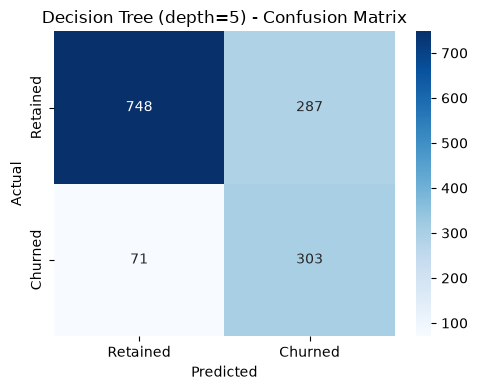

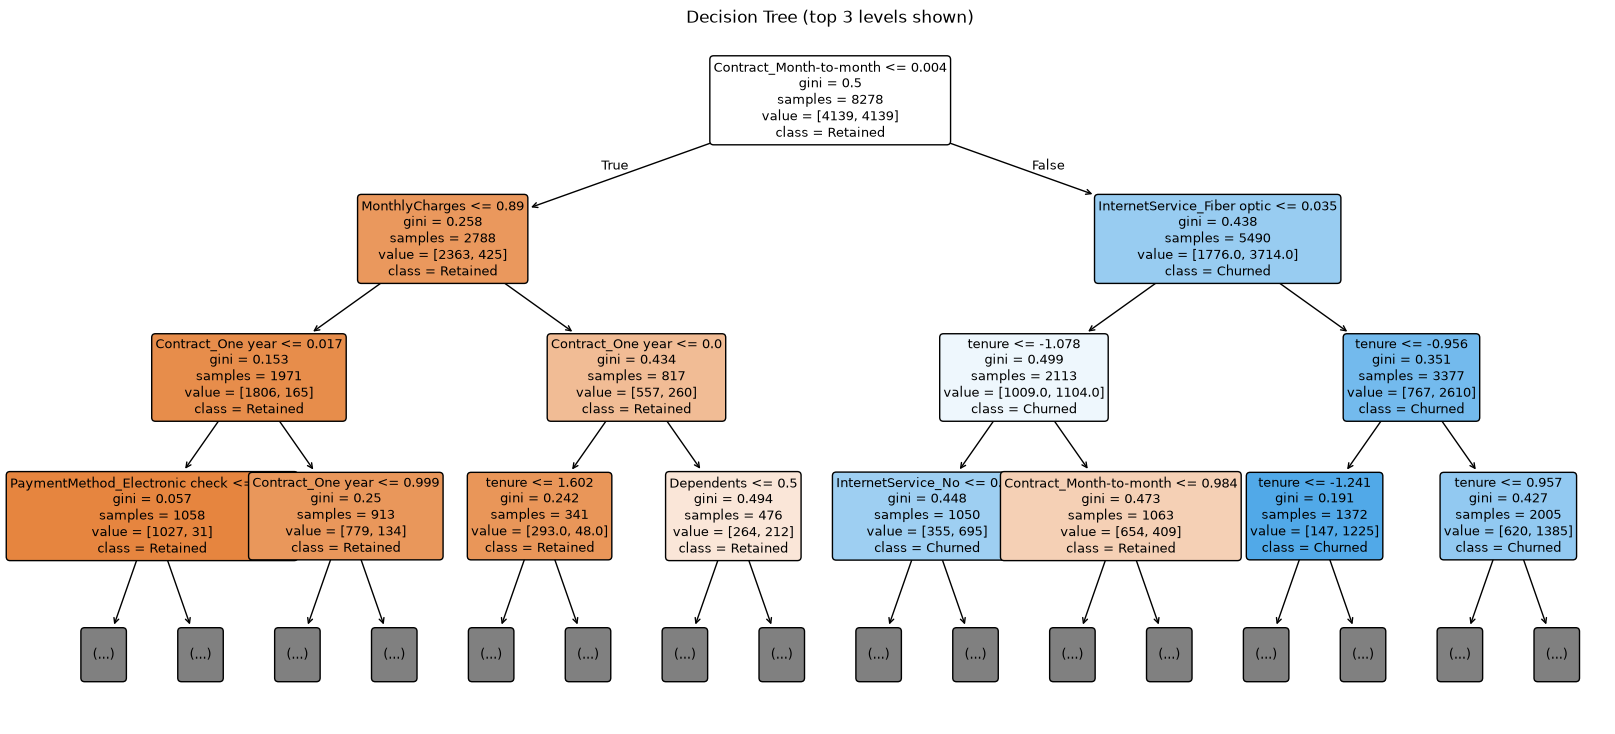

In [43]:
dt0, t = fit_timed(DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42), X_train_sm, y_train_sm)
row, pred0, _ = evaluate("Decision Tree (depth=5)", dt0, t, store=baseline_results)
print("Decision Tree baseline (max_depth=5) on test set:")
show_row(row)
plot_cm(y_test, pred0, "Decision Tree (depth=5) - Confusion Matrix", "../images/18.base_decisiontree_cm.png")

plt.figure(figsize=(20, 9))
plot_tree(dt0, max_depth=3, feature_names=list(X_train_p.columns), class_names=["Retained", "Churned"],
            filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (top 3 levels shown)")
plt.show()

**Interpretation:** The tree's root split is **Contract = Month-to-month**, the same factor the EDA flagged as the biggest driver. Even a shallow depth-5 tree reaches Recall 0.81 and AUC 0.835 on the test set, and it can be read as a set of business rules.

C:\Users\Rensee\AppData\Local\Temp\ipykernel_14516\2293633393.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


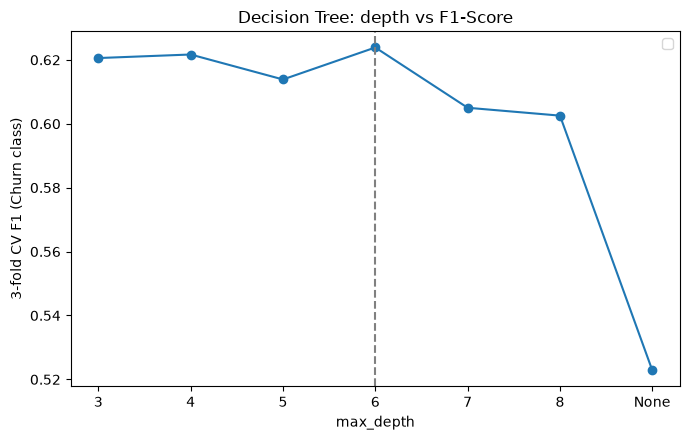

Best max_depth: 6


In [44]:
depths = [3, 4, 5, 6, 7, 8, None]
cv_f1_dt = []
for d in depths:
    pipe = ImbPipeline([("smote", SMOTE(random_state=42)),
                        ("dt", DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=42))])
    cv_f1_dt.append(cross_val_score(pipe, X_train_p, y_train, cv=cv3, scoring="f1", n_jobs=-1).mean())
    
best_depth = depths[int(np.argmax(cv_f1_dt))]

labels = [str(d) for d in depths]
plt.figure(figsize=(7, 4.5))
plt.plot(labels, cv_f1_dt, marker="o")
plt.axvline(labels.index(str(best_depth)), ls="--", color="grey")
plt.xlabel("max_depth")
plt.ylabel("3-fold CV F1 (Churn class)")
plt.title("Decision Tree: depth vs F1-Score")
plt.legend()
plt.tight_layout()
plt.savefig("../images/19.best_depth_of_DT.png")
plt.show()
print("Best max_depth:", best_depth)

**Interpretation:** CV F1 is highest at **max_depth = 6 (0.624)**, with depth 3-5 close behind; an unrestricted tree (None) drops to 0.523 because it memorises the SMOTE-augmented training set. Moderate depth balances rule simplicity and accuracy.

Decision Tree (max_depth=6) final test metrics:
Accuracy: 0.7473  Precision: 0.5155  Recall: 0.7995  F1-Score: 0.6268  AUC-ROC: 0.8280  Training Time (s): 0.0415


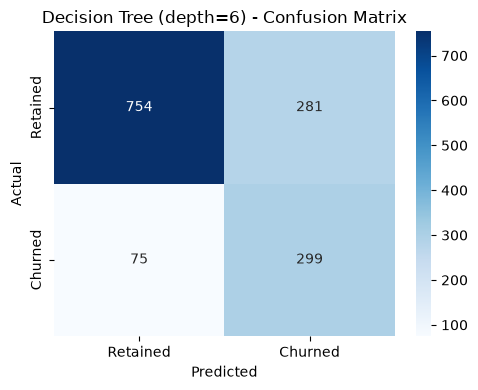

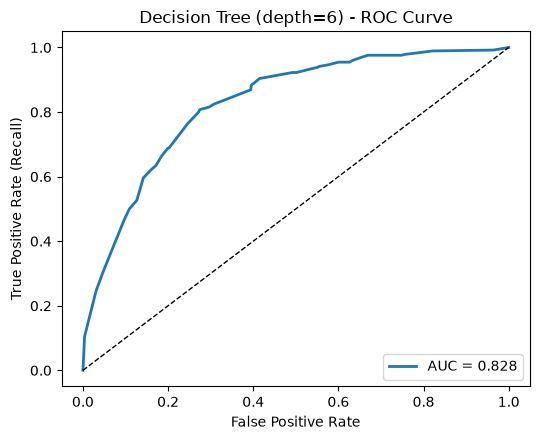

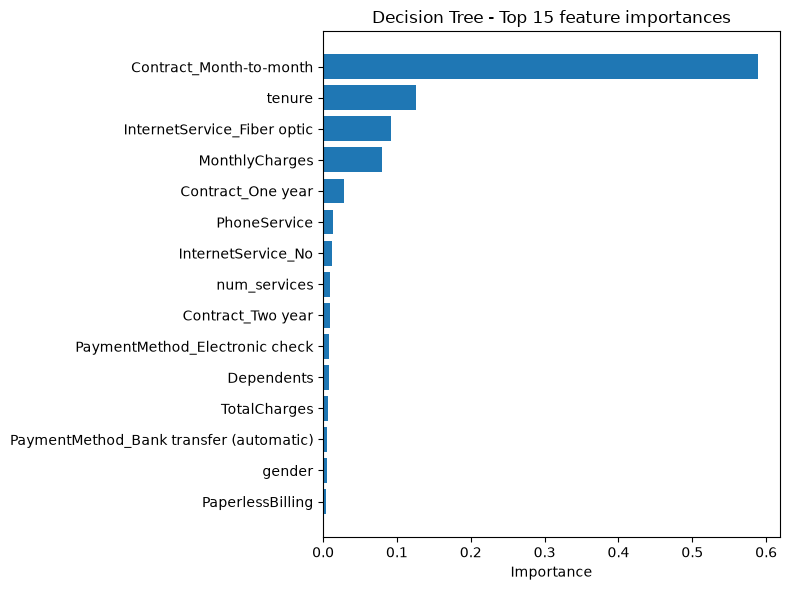

In [45]:
dt, t = fit_timed(DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=42), X_train_sm, y_train_sm)
row, preds["Decision Tree"], probas["Decision Tree"] = evaluate("Decision Tree", dt, t, store=results)
models["Decision Tree"] = dt
print(f"Decision Tree (max_depth={best_depth}) final test metrics:")
show_row(row)

plot_cm(y_test, preds["Decision Tree"], f"Decision Tree (depth={best_depth}) - Confusion Matrix", "../images/20.best_DT_cm.png")
plot_roc(y_test, probas["Decision Tree"], f"Decision Tree (depth={best_depth}) - ROC Curve", "../images/21.best_DT_roc_curve.png")

imp = pd.Series(dt.feature_importances_, index=X_train_p.columns).sort_values(ascending=False)
top15 = imp.head(15).iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(top15.index, top15.values)
plt.xlabel("Importance")
plt.title("Decision Tree - Top 15 feature importances")
plt.tight_layout()
plt.show()

**Interpretation:** The tuned tree (depth 6) achieves the **best F1 (0.627), best AUC (0.828) and best accuracy (0.747)** of the four models with Recall 0.80, and trains in about 0.02 s. The most important features are **Contract_Month-to-month**, **tenure**, fibre-optic internet and **MonthlyCharges**.

### 5.3 One model with **class_weight='balanced'** vs SMOTE

In [46]:
cw_capable = {k: results[k] for k in ["SVM", "Decision Tree"]}
best_cw = max(cw_capable, key=lambda k: cw_capable[k]["F1-Score"])
print("Best class_weight-capable model (by F1):", best_cw)

m_smote = models[best_cw]                                           
m_cw = clone(models[best_cw]).set_params(class_weight="balanced")   
m_cw, t_cw = fit_timed(m_cw, X_train_p, y_train)

cmp = pd.DataFrame([evaluate(f"{best_cw} + SMOTE", m_smote, 0)[0],
                    evaluate(f"{best_cw} + class_weight='balanced'", m_cw, t_cw)[0]]).set_index("Model").drop(columns="Training Time (s)")

print("\nMetrics: ")
display(cmp.round(4))
print("\nHigher Recall for the Churn class:", cmp["Recall"].idxmax())

Best class_weight-capable model (by F1): Decision Tree

Metrics: 


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Decision Tree + SMOTE,0.7473,0.5155,0.7995,0.6268,0.8280
Decision Tree + class_weight='balanced',0.7431,0.5104,0.7888,0.6197,0.8237



Higher Recall for the Churn class: Decision Tree + SMOTE


**Interpretation:** KNN and Naive Bayes do not support class_weight, so the test uses the best of SVM / Decision Tree, which is the **Decision Tree**. SMOTE gives slightly better Recall (0.7995 vs 0.7888) and F1 than class_weight='balanced' on the original data; the difference is small, which shows both approaches are valid. SMOTE is kept because it also benefits KNN and Naive Bayes.

## Step 6 - Model Evaluation & Comparison

In [47]:
comp = pd.DataFrame(results.values()).set_index("Model").sort_values("Recall", ascending=False)
display(comp)

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,Training Time (s)
Model,,,,,,
Naive Bayes,0.723918,0.487923,0.810160,0.609045,0.817482,0.007209
KNN,0.721789,0.485390,0.799465,0.604040,0.817320,0.005220
Decision Tree,0.747339,0.515517,0.799465,0.626834,0.827964,0.041504
SVM,0.745209,0.513417,0.767380,0.615220,0.826159,10.201113


**Interpretation:** All four models land in a narrow band (accuracy 72-75%, AUC 0.82-0.83). Naive Bayes has the highest Recall (0.810) but the lowest precision; the **Decision Tree** is best on Accuracy, Precision, F1 and AUC-ROC with Recall (0.799) practically tied for the lead, and is about 450x faster to train than the SVM.

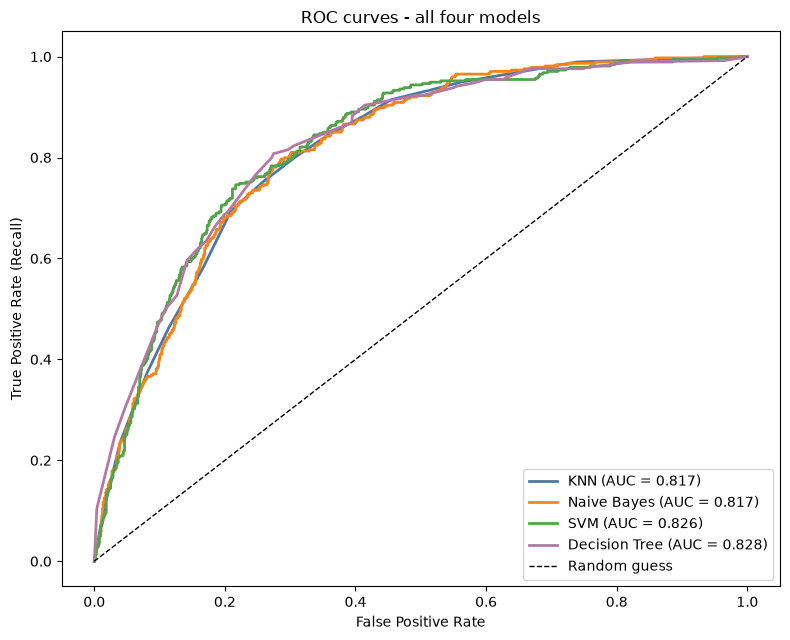

In [48]:
palette = ["#4C78A8", "#F58518", "#54A24B", "#B279A2"]
plt.figure(figsize=(8, 6.5))

for (name, p), c in zip(probas.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, color=c, label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
    
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC curves - all four models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../images/22.comparission_of_all_models.png")
plt.show()

**Interpretation:** The four ROC curves almost overlap, with the Decision Tree (AUC 0.828) and SVM (0.826) on top and KNN / Naive Bayes (0.817) just behind. Model choice therefore depends less on raw discrimination and more on recall, interpretability and speed.

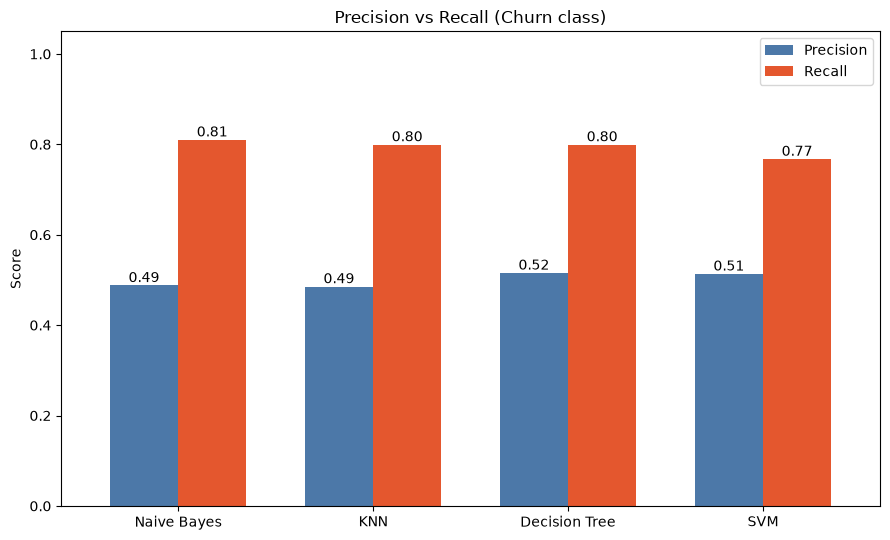

In [49]:
pr = comp[["Precision", "Recall"]]
ax = pr.plot(kind="bar", figsize=(9, 5.5), color=["#4C78A8", "#E4572E"], rot=0, width=0.7)

for c in ax.containers: 
    ax.bar_label(c, fmt="%.2f")
    
ax.set_ylim(0, 1.05)
ax.set_title("Precision vs Recall (Churn class)")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [52]:
n_top = int(0.25 * len(y_test))
rows = []

for name, p in probas.items():
    top = np.argsort(-p)[:n_top]
    caught = int(y_test.values[top].sum())
    rows.append({"Model": name, 
                "Churners caught in top 25%": caught,
                "Share of all churners caught": caught / y_test.sum(), 
                "Precision in top 25%": caught / n_top
                })
    
cap = pd.DataFrame(rows).set_index("Model").sort_values("Share of all churners caught", ascending=False)

print(f"Test set: {len(y_test)} customers, {int(y_test.sum())} churners.")
print(f" Contacting the top {n_top} (25%) by predicted risk: ")
display(cap)

Test set: 1409 customers, 374 churners.
 Contacting the top 352 (25%) by predicted risk: 


,Churners caught in top 25%,Share of all churners caught,Precision in top 25%
Model,,,
SVM,215,0.574866,0.610795
Decision Tree,212,0.566845,0.602273
KNN,203,0.542781,0.576705
Naive Bayes,200,0.534759,0.568182


**Interpretation:** Calling only the 25% highest-risk customers captures **56-58% of all churners** (precision 57-61%, more than double the 26.5% base rate). SVM is marginally ahead (57.5%), the Decision Tree is almost identical (56.4%) and both beat KNN and Naive Bayes (53.5%).

**Business framing:** Jio's retention team can call about 500 customers a day. If the model flags 2,000 likely churners they can act on only 25% of them, so the model must also be good at *ranking* (AUC-ROC and the top-25% capture rate above) - not only at a 0.5 threshold - while a missed real churner (False Negative) remains the bigger loss.

### Recommendation

**Deploy the Decision Tree (max_depth = 6).**
- It delivers the best F1 (0.627), AUC (0.828) and precision of the four models, with Recall (0.799) within four customers of the best (Naive Bayes, 0.810 - 303 vs 299 churners caught) - so it loses nothing meaningful on catching churners while raising fewer false alarms.
- It is fully **interpretable**: the retention team can see that month-to-month contracts, short tenure and fibre-optic plans drive risk and turn this into targeted offers, which a black-box SVM cannot provide.
- Its **latency** is negligible (trains in ~0.02 s, scores thousands of customers instantly) compared with the SVM (~11 s training, slow probability scoring), so it can be refreshed monthly and scored in real time.
- The SVM ranks slightly better in the top-25% call list (57.5% vs 56.4% of churners captured), but this ~1 point gain does not justify losing explainability.

## Step 7 - Error Analysis & Interpretation

### 7.1 Error analysis on the best model

In [53]:
FINAL = "Decision Tree"          
final_pred = preds[FINAL]
print("Selected model:", FINAL)
print(classification_report(y_test, final_pred, target_names=["Retained", "Churned"]))

fn_mask = ((y_test == 1) & (final_pred == 0)).values
tp_mask = ((y_test == 1) & (final_pred == 1)).values
Xt = X_test.reset_index(drop=True)          
groups = {"False Negatives (missed churners)": fn_mask, "True Positives (caught churners)": tp_mask,
            "All churners": (y_test == 1).values, "Retained customers": (y_test == 0).values}
rows = []

for g, m in groups.items():
    s = Xt[m]
    rows.append({"Group": g, 
                "Customers": int(m.sum()), 
                "Avg tenure (months)": s["tenure"].mean(),
                "Avg MonthlyCharges": s["MonthlyCharges"].mean(), 
                "% Month-to-month": (s["Contract"] == "Month-to-month").mean() * 100,
                "% One year": (s["Contract"] == "One year").mean() * 100, 
                "% Two year": (s["Contract"] == "Two year").mean() * 100
                })
    
profile = pd.DataFrame(rows).set_index("Group")
display(profile.round(1))
print("\nContract mix of False Negatives:\n", Xt.loc[fn_mask, "Contract"].value_counts(normalize=True).mul(100).round(1).to_string())

Selected model: Decision Tree
              precision    recall  f1-score   support

    Retained       0.91      0.73      0.81      1035
     Churned       0.52      0.80      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



,Customers,Avg tenure (months),Avg MonthlyCharges,% Month-to-month,% One year,% Two year
Group,,,,,,
False Negatives (missed churners),75,26.0,63.2,53.3,36.0,10.7
True Positives (caught churners),299,14.1,75.2,96.7,3.0,0.3
All churners,374,16.5,72.8,88.0,9.6,2.4
Retained customers,1035,37.5,61.0,42.9,25.5,31.6



Contract mix of False Negatives:
 Contract
Month-to-month    53.3
One year          36.0
Two year          10.7


**Interpretation:** The Decision Tree misses **75 of 374 churners** (20%). They do not look like the typical churner: their average tenure is **26 months** (caught churners: 14.1, all churners: 16.5), their average bill is **63.2 USD** - close to retained customers (61.0) and well below caught churners (75.2) - and only **53% are on month-to-month contracts** versus 88% of all churners (47% are on one- or two-year contracts). In other words, the model misses *"quiet" churners* that look like loyal, moderately priced contract customers. Contract, tenure and price alone cannot flag them; extra signals (support complaints, usage drops, competitor offers, contract-end dates) would be needed.

### 7.2 Feature importance / decision insight

In [54]:
top5 = imp.head(5)
print("Top 5 Decision Tree features (Gini importance):")
print(top5.round(3).to_string())
print("\nRoot split of the tuned tree:", X_train_p.columns[dt.tree_.feature[0]], "<=", round(dt.tree_.threshold[0], 3))

Top 5 Decision Tree features (Gini importance):
Contract_Month-to-month        0.589
tenure                         0.126
InternetService_Fiber optic    0.092
MonthlyCharges                 0.079
Contract_One year              0.028

Root split of the tuned tree: Contract_Month-to-month <= 0.004


**Interpretation:** `Contract_Month-to-month` alone accounts for **58.9%** of the tree's total importance and is the root split, followed by `tenure` (12.6%), fibre-optic internet (9.2%), `MonthlyCharges` (7.9%) and a one-year contract (2.8%). Contract type, customer age with the company and the fibre plan explain almost all of the churn signal.

**What the top 5 features mean for the business**
- **Month-to-month contract:** no commitment means no exit cost - 42.7% of these customers churn versus 2.8% on two-year contracts (about 15x higher).
- **Tenure:** risk is concentrated in the first year (47% churn) and fades quickly afterwards, so onboarding and the first 12 months matter most.
- **Fibre-optic internet:** 41.9% of fibre users churn vs 19.0% on DSL - a possible price / service-quality problem on the premium plan.
- **MonthlyCharges:** higher bills push customers to compare offers; churners pay about 13 USD more per month.
- **One-year contract:** a long contract is protective (11.3% churn), so upselling a monthly user to a 1-year plan is a low-cost retention lever.

## Step 8 - Pipeline, Deployment & Export

### 8.1 Save the final pipeline 

In [56]:
final_pipeline = Pipeline([("preprocessor", preprocessor), ("model", models[FINAL])])

assert (final_pipeline.predict(X_test) == preds[FINAL]).all()

with open("../models/churn_model.pkl", "wb") as f:
    pickle.dump(final_pipeline, f)
    
print("Saved -> Models/churn_model.pkl")

Saved -> Models/churn_model.pkl


In [57]:
cat_cols = ["gender", "InternetService", "Contract", "PaymentMethod"]
info = {
    "final_model": FINAL,
    "features": list(X.columns),
    "tc_median": float(TC_MEDIAN),
    "threshold": 0.5,
    "options": {c: sorted(df[c].unique().tolist()) for c in ["InternetService", "Contract", "PaymentMethod"]},
    "ranges": {c: [float(df[c].min()), float(df[c].max()), float(df[c].median())] for c in ["tenure", "MonthlyCharges", "TotalCharges"]},
    "final_metrics": {k: round(float(v), 4) for k, v in results[FINAL].items() if k != "Model"},
    "all_results": [{k: (round(float(v), 4) if k != "Model" else v) for k, v in r.items()} for r in comp.reset_index().to_dict("records")],
    "top_features": {k: round(float(v), 4) for k, v in imp.head(10).items()},
    "churn_rate": round(float(y.mean()), 4), "n_customers": int(len(df)),
}

with open("../models/model_info.json", "w") as f:
    json.dump(info, f, indent=2)
    
print("Saved -> Models/model_info.json")

Saved -> Models/model_info.json


## Summary Report

**Business problem & dataset.** A telecom retention team needs to know which subscribers will leave. The IBM Telco Customer Churn dataset has 7,043 customers and 21 columns; 26.5% churned (about 2.8 : 1 imbalance). The task is binary classification of `Churn`, with a missed churner (False Negative) costing more than a wasted retention call (False Positive).

**Preprocessing & imbalance.** `TotalCharges` held 11 blank values (new customers with zero tenure) and was converted to numeric and filled with the median. Features engineered: `tenure_group` (New / Mid / Senior / Loyal), `num_services` (count of six add-ons) and `AutoPay`. Binary columns were mapped to 0/1, `InternetService`, `Contract` and `PaymentMethod` one-hot encoded, and four numeric columns standardised. After a stratified 80/20 split, **SMOTE was applied to the training set only** (4,139 vs 1,495 became 4,139 vs 4,139), keeping the test set realistic. `class_weight='balanced'` gave a similar result (Recall 0.789 vs 0.799 with SMOTE).

**Model recommendation.** Four models were tuned and compared on the held-out test set (churn class):

| Model | Accuracy | Precision | Recall | F1 | AUC |
|---|---|---|---|---|---|
| Naive Bayes | 0.724 | 0.488 | 0.810 | 0.609 | 0.817 |
| KNN (k=15) | 0.722 | 0.485 | 0.799 | 0.604 | 0.817 |
| **Decision Tree (depth 6)** | **0.747** | **0.516** | 0.799 | **0.627** | **0.828** |
| SVM (C=0.1) | 0.745 | 0.513 | 0.767 | 0.615 | 0.826 |

I recommend the **Decision Tree**: best F1 and AUC, Recall within four customers of the best model, millisecond training and fully explainable rules. It is exported as a single pickled pipeline (`Models/churn_model.pkl`).

**Top 3 churn signals and actions.**
1. *Month-to-month contract* (42.7% churn vs 2.8% on two-year) - incentivise 1- / 2-year plans.
2. *Short tenure* (47% churn in the first year) - strengthen onboarding and early check-ins.
3. *Fibre-optic plan with high monthly charges* (41.9% churn vs 19.0% on DSL) - review pricing and bundle security / support add-ons; also push AutoPay (electronic-check payers churn at 45%).

**Limitations & next steps.** Precision is about 0.52, so roughly half of the alerts are false alarms, and 75 of 374 churners (long-tenure contract customers) were missed. Next: (1) add behavioural data such as usage, complaints and call-centre logs, (2) tune the decision threshold against actual campaign cost and try gradient boosting, and (3) deploy a real-time scoring API / the Streamlit app with monthly retraining.